# 02 · 抽样波动、置信区间与检验功效

## 目标 · Goal

区分总体分布、样本均值的抽样分布、区间程序的覆盖率和检验的功效。相同图形中的横轴含义必须说清楚。
需要的准备：均值、方差、正态分布、概率事件。

## 准备 · Setup

先在网页预测结果、拖动参数，再回到这里复算。代码只使用合成数据，不读取学习记录。
所有随机数使用 NumPy PCG64；固定种子可重现本 Notebook，**不意味着与网页的随机样本逐项一致**。
数学定义、参数和边界与网页一致。独立核验脚本另外直接读取网页原始样本，再用 NumPy/SciPy 复算。

运行环境：Python 3.12+，依赖见 `../requirements.txt`。从顶部顺序运行全部单元格；图表标签用英语，讲解用中文。

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "python"]
source_dir = next((p for p in candidates if (p / "lab_reference.py").is_file()), None)
if source_dir is None:
    raise FileNotFoundError("从 python/notebooks 或 python 目录运行此 Notebook")
sys.path.insert(0, str(source_dir))
import numpy as np
from scipy.stats import norm, beta as beta_distribution
from numpy.polynomial.legendre import legvander
import matplotlib.pyplot as plt
import lab_reference as lab
%matplotlib inline
plt.rcParams.update({"figure.figsize": (9, 4.4), "figure.dpi": 125,
                     "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .18, "axes.axisbelow": True})
BLUE, ORANGE, OLIVE, INK = "#24658c", "#bc6327", "#69743a", "#24323c"
SEED = 42
print("NumPy", np.__version__, "· seed", SEED, "· independent PCG64 draws")

NumPy 2.5.3 · seed 42 · independent PCG64 draws


## 实验 5 · 大数定律与中心极限定理的条件

正态与 Exp(1) 的总体方差都为 1，均值的理论标准误差为 $1/\sqrt n$。
标准 Cauchy 的总体均值和方差均未定义；不能把它代入这里的有限方差中心极限定理。
Cauchy 样本均值仍是标准 Cauchy，因此增大样本量不会让它按同样方式集中。

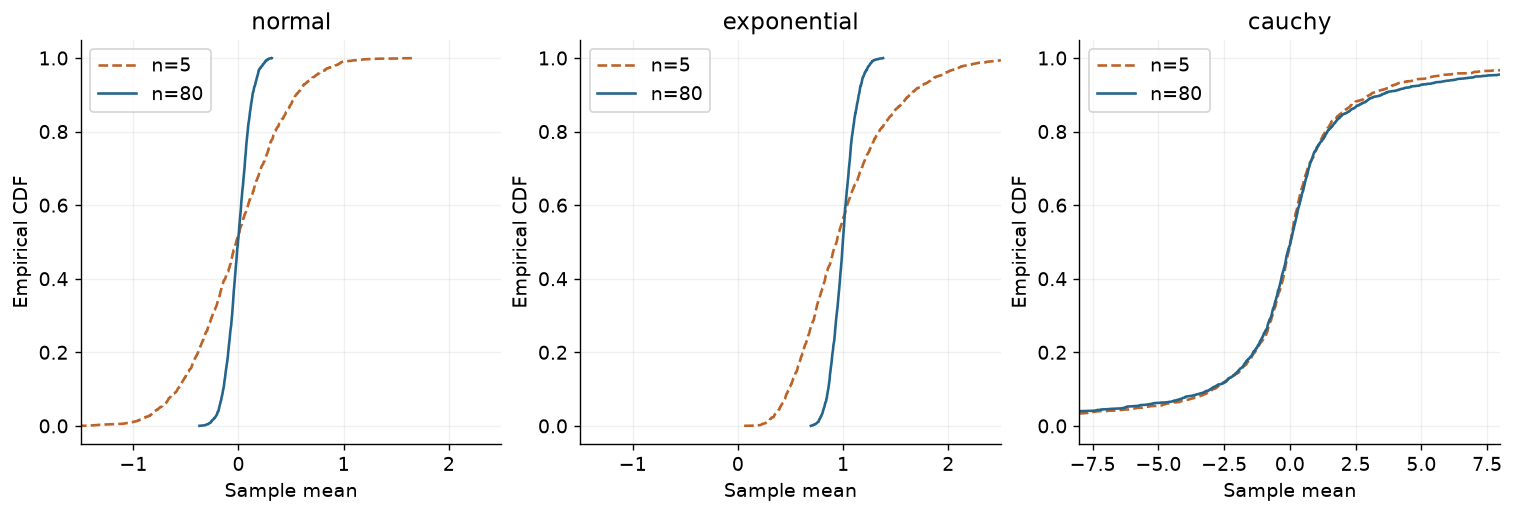

Cauchy CDF panel shows x in [-8, 8]; tails extend beyond the displayed window.
normal empirical SE 0.1099 theory 0.1118
exponential empirical SE 0.1126 theory 0.1118


In [2]:
fig,axes=plt.subplots(1,3,figsize=(12,4),layout="constrained")
for ax,distribution in zip(axes,["normal","exponential","cauchy"]):
    for n,color,style in [(5,ORANGE,"--"),(80,BLUE,"-")]:
        r=lab.compute("sampling",n=n,reps=2000,distribution=distribution,seed=SEED)
        values=np.sort(r["means"]); probabilities=np.arange(1,len(values)+1)/len(values)
        ax.plot(values,probabilities,style,color=color,label=f"n={n}")
    ax.set(xlabel="Sample mean",ylabel="Empirical CDF",title=distribution)
    ax.set_xlim((-8,8) if distribution=="cauchy" else (-1.5,2.5)); ax.legend()
plt.show()
print("Cauchy CDF panel shows x in [-8, 8]; tails extend beyond the displayed window.")
for distribution in ["normal","exponential"]:
    r=lab.compute("sampling",n=80,reps=2000,distribution=distribution,seed=SEED)
    print(distribution,"empirical SE",round(r["means"].std(ddof=1),4),"theory",round(r["theoreticalSE"],4))
assert lab.compute("sampling",distribution="cauchy")["theoreticalSE"] is None

这里用经验累积分布避免 Cauchy 的极端值把直方图主体压成一条线；尾部仍然存在，并未被删除后重新归一化。

**自己试：** 固定种子改变 `n`，观察正态与 Cauchy 的中间 50% 宽度。解释为什么有限样本里总能算出一个数，不等于总体期望存在。

## 实验 6 · 95% 是区间程序的长期覆盖率

已知 $\sigma$，且 $X_i\overset{iid}{\sim}N(\mu,\sigma^2)$ 时，
$\bar X\pm z_{(1+c)/2}\sigma/\sqrt n$ 是精确覆盖率为 $c$ 的区间程序。
本实验固定真实 $\mu=0$；重复生成数据，每次区间不同。单个已观察区间不对固定参数赋予频率派概率。

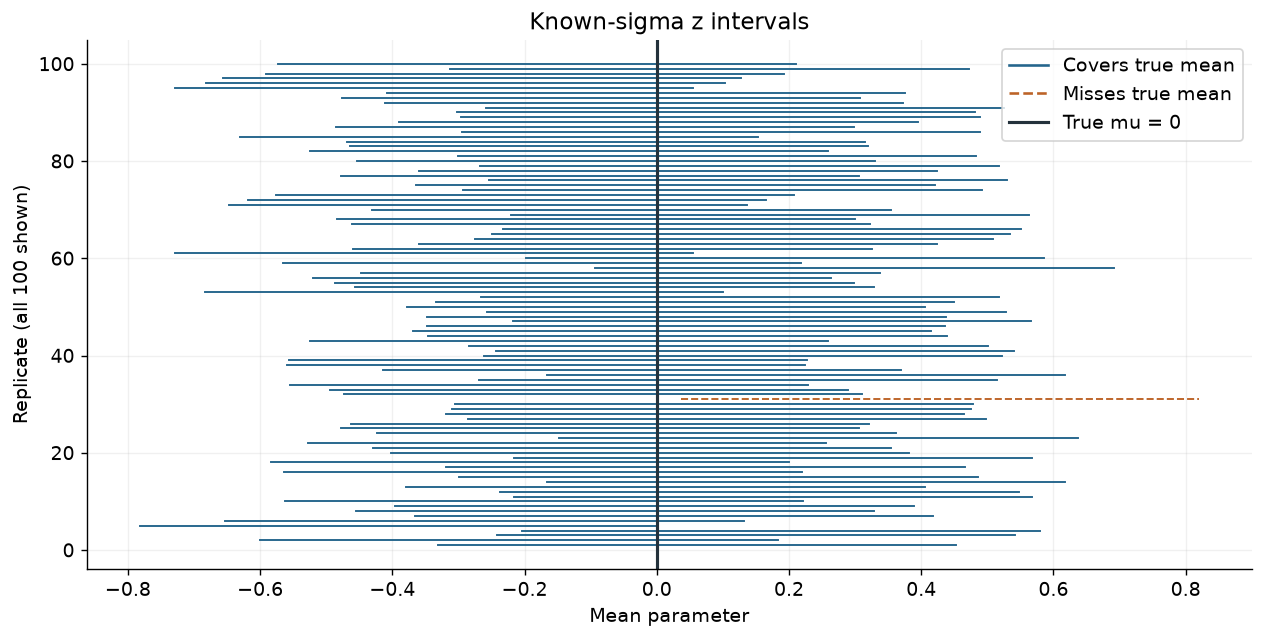

Coverage 99/100 = 99.0%; interval width 0.7840
Monte Carlo SE under nominal 95% coverage = 0.0218


In [3]:
r=lab.compute("confidence",n=25,reps=100,level=.95,sigma=1,seed=SEED)
fig,ax=plt.subplots(figsize=(10,5),layout="constrained")
for i,(low,high,covers) in enumerate(zip(r["low"],r["high"],r["covered"])):
    ax.plot([low,high],[i+1,i+1],"-" if covers else "--",color=BLUE if covers else ORANGE,linewidth=1.1)
ax.plot([],[],"-",color=BLUE,label="Covers true mean")
ax.plot([],[],"--",color=ORANGE,label="Misses true mean")
ax.axvline(0,color=INK,linewidth=1.8,label="True mu = 0")
ax.set(xlabel="Mean parameter",ylabel="Replicate (all 100 shown)",title="Known-sigma z intervals"); ax.legend()
plt.show()
print(f"Coverage {r['covered'].sum()}/100 = {r['coverage']:.1%}; interval width {r['width']:.4f}")
print(f"Monte Carlo SE under nominal 95% coverage = {r['monteCarloSE']:.4f}")
assert np.allclose(r["high"]-r["low"],r["width"])
assert np.isclose(lab.compute("confidence",n=100)["width"],r["width"]/2)

一次重复实验的覆盖率可以高于或低于 95%。重复次数控制模拟估计的精度，样本量控制每个区间的宽度；这两个数量不能互换。

**自己试：** 固定样本量，把重复次数从 100 改成 300；再固定重复次数，把样本量变为四倍。分别预测 Monte Carlo 标准误差和区间宽度如何变化。

## 实验 7 · p 值与功效回答不同的问题

$H_0:\mu=0$，已知 $\sigma=1$，双侧拒绝域为 $|Z|>z_{1-\alpha/2}$。
当真实均值为 $\delta$ 时，$Z\sim N(\delta\sqrt n,1)$；两侧尾面积之和给出**精确功效**。
p 值在零假设分布下计算，不是零假设为真的概率。

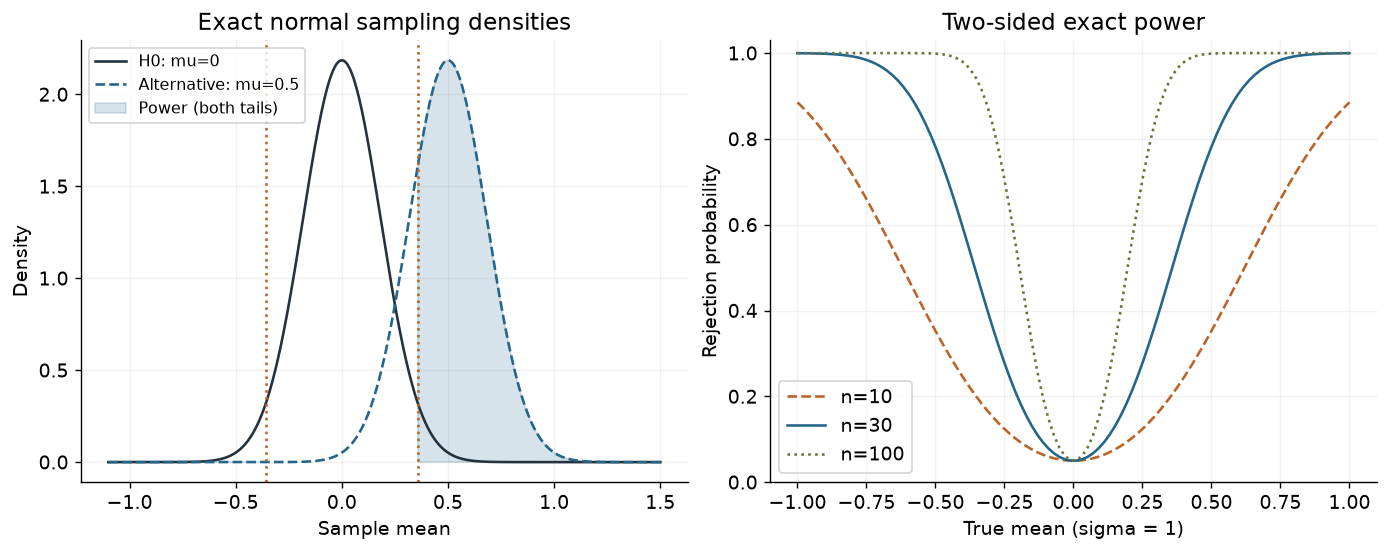

Observed p-value = 0.100348; power at effect 0.5 = 0.781908


In [4]:
n, effect, alpha, observed = 30, .5, .05, .3
r=lab.compute("testing",n=n,effect=effect,alpha=alpha,observed=observed)
x=np.linspace(-1.1,1.5,600); se=1/np.sqrt(n)
fig,axes=plt.subplots(1,2,figsize=(11,4.3),layout="constrained")
axes[0].plot(x,norm.pdf(x,0,se),color=INK,label="H0: mu=0")
axes[0].plot(x,norm.pdf(x,effect,se),"--",color=BLUE,label=f"Alternative: mu={effect}")
rejected=np.abs(x)>r["criticalMean"]
axes[0].fill_between(x,0,norm.pdf(x,effect,se),where=rejected,color=BLUE,alpha=.18,label="Power (both tails)")
for cutoff in [-r["criticalMean"],r["criticalMean"]]: axes[0].axvline(cutoff,color=ORANGE,linestyle=":")
axes[0].set(xlabel="Sample mean",ylabel="Density",title="Exact normal sampling densities"); axes[0].legend(fontsize=9)
effects=np.linspace(-1,1,100)
for size,color,style in [(10,ORANGE,"--"),(30,BLUE,"-"),(100,OLIVE,":")]:
    power=[lab.compute("testing",n=size,effect=e)["power"] for e in effects]
    axes[1].plot(effects,power,style,color=color,label=f"n={size}")
axes[1].set(xlabel="True mean (sigma = 1)",ylabel="Rejection probability",ylim=(0,1.03),title="Two-sided exact power"); axes[1].legend()
plt.show()
print(f"Observed p-value = {r['pValue']:.6f}; power at effect {effect} = {r['power']:.6f}")
assert np.isclose(lab.compute("testing",effect=0)["power"],.05)
assert np.isclose(lab.compute("testing",effect=-.5)["power"],r["power"])

## 检查 · Checks

核对了 Cauchy 未定义的理论标准误差、区间宽度的 $1/\sqrt n$ 比例、零效应下功效等于显著性水平，以及双侧功效的对称性。

## 接下来 · Next steps

固定 `observed` 改变假定真实效应 `effect`：功效变化，p 值不应变化。解释这为什么不是矛盾。

来源：[SciPy 正态分布定义与 CDF/SF](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)、[NIST 置信区间解释](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)（用于覆盖率含义；该页面公式本身是未知方差 t 区间，本实验已知方差 z 公式直接由正态标准化得到）、[NIST Cauchy 分布](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3663.htm)。